In [ ]:
import pandas as pd
import numpy as np
from collections import Counter                                                 # count occurance of element
import matplotlib.pyplot as plt
import re                                                                       # regular expression: replacing, search, etc
import nltk                                                                     # Natural language toolkit

from autocorrect import Speller                                                 # check and correct sentence
from nltk.corpus import stopwords                                               #filter out stopwords

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC                                               # Linear Support Vector Classification
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

import pdb                                                                      # debugger

In [ ]:
#from google.colab import drive  # mount drive
#drive.mount('/content/drive')

#import os
#path = "/content/drive/MyDrive/ECE 537 Project/ECE537DataMining/Dataset/"
import os
path = "C:/Users/Abdul/Downloads/"

## Import the Data

In [ ]:
df = pd.read_csv(path+'final_data.csv', header=None)                            # file path is changed to import csv
# df.rename(columns={0: 'comment', 1: 'category'}, inplace=True)

## Exploring the Data

In [ ]:
# Printing unique category
df[1].unique()

array(['positive', 'imperative', 'interrogative', 'miscellaneous',
       'corrective', 'negative'], dtype=object)

In [ ]:
# removing duplicate rows

df = df.drop_duplicates()                                                       # remove duplicated rows
df.duplicated().any()                                                           # check

df = df.reset_index(drop=True)                                                  # reset index to avoid issue in loop with no index for duplicated row


In [ ]:
# Checking null values
df.isnull().sum()

0    0
1    0
dtype: int64

In [ ]:
# Checking the shape of the data
df.shape

(9787, 2)

## Preprocessing

In [ ]:
# Preprocessing

# lowercasing
df[0] = df[0].str.lower()

# removing urls
df[0] = df[0].str.replace('http\S+|www.\S+', '', case=False)

# removing new lines "\n"
df[0] = df[0].str.replace('\n',' ', regex=True)

# removing all the punctuations
df[0] = df[0].str.replace('[^\w\s]',' ')

# removing integers
df[0] = df[0].str.replace('\d','', regex=True)

# removing emojis
df[0] = df[0].str.replace('[^\w\s#@/:%.,_-]', ' ', flags=re.UNICODE)
df

,0,1
0,love you sir!!,positive
1,please make videos on..midpoint circle drawing...,imperative
2,i bought both of your courses on udemy. you ar...,interrogative
3,"thank you very much, u really got me in the fi...",positive
4,i hope u are ok with everything going on again...,miscellaneous
...,...,...
9782,this is gold! absolute peach of a video. but i...,positive
9783,"this is helpful, how to decode a logical conte...",interrogative
9784,wow. reading this slowly actually helped me se...,positive
9785,"great video sir, really helped a lot.keep goin...",positive


In [ ]:
# df.rename(columns={'comment':0, 'category':1}, inplace=True)
# df

In [ ]:
# correcting the typos (modified code to show the difference)
df['text']=df[0]

spell = Speller(lang='en')

df['corrected_text'] = df['text'].apply(spell)

# Display the original and corrected text side by side
df['corrections'] = df.apply(lambda row: [corrected_text for text, corrected_text in
                                          zip(row['text'].split(), row['corrected_text'].split())
                                          if text != corrected_text], axis=1)
df
df[0] = df['corrected_text']                                                    #overwrite first columne by corrected text for next step

In [ ]:
from spellchecker import SpellChecker #typo correction
import pandas as pd

# Assuming df is your DataFrame
# Assuming '0' is the column containing YouTube comments

# Initialize the spell checker
spell = SpellChecker(language='en')

# Define the typo corrector function
def typo_corrector(text):
    # Check if the value is a string
    if isinstance(text, str):
        return spell.correction(text)
    else:
        return text

# Apply spell checker to the specific column in the DataFrame
#df['0'] = df['0'].apply(typo_corrector)

# Apply spell checker to the first column in the DataFrame
df.iloc[:, 0] = df.iloc[:, 0].apply(typo_corrector)

# Display the DataFrame with corrected comments
#print(df['0'])

# Display the DataFrame with corrected comments
print(df.iloc[:, 0])



0                                                    None
1       please make videos on..midpoint circle drawing...
2       i bought both of your courses on dmy. you are ...
3       thank you very much, u really got me in the fi...
4       i hope u are ok with everything going on again...
                              ...                        
9782    this is gold! absolute peach of a video. but i...
9783    this is helpful, how to decode a logical conte...
9784    wow. reading this slowly actually helped me se...
9785    great video sir, really helped a lot.keep goin...
9786    oh damn! u deserve a lot many subscribers than...
Name: 0, Length: 9787, dtype: object


In [ ]:
#import nltk                                                                     # Natural language toolkit
#nltk.download('wordnet')
#from nltk.stem import WordNetLemmatizer
#from nltk.tokenize import word_tokenize
#nltk.download('punkt')  # Download the punkt tokenizer

#df['text']=df[0]

# lemmatizing
#lemmatizer = nltk.stem.WordNetLemmatizer()                                      # word format changing

#def lemmatize_sentence(sentence):
#    lemmatizer = WordNetLemmatizer()
#    words = word_tokenize(sentence)                                             # Tokenize the sentence into words
#    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
#    lemmatized_sentence = ' '.join(lemmatized_words)
#    return lemmatized_sentence

# Display the original and lemmatized text side by side
#df['lemmatized_text'] = df['text'].apply(lemmatize_sentence)
#df['temp_lemma'] = df.apply(lambda row: [lemmatized_text for text, lemmatized_text in
#                                          zip(row['text'].split(), row['lemmatized_text'].split())
#                                          if text != lemmatized_text], axis=1)

#df[0] = df['lemmatized_text']

#df

In [ ]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
nltk.download('wordnet')
nltk.download('punkt')

df['text'] = df[0]

# lemmatizing
lemmatizer = nltk.stem.WordNetLemmatizer()

def lemmatize_sentence(sentence):
    lemmatizer = WordNetLemmatizer()
    # Check for None values and replace them with an empty string
    words = word_tokenize(sentence) if sentence is not None else []
    lemmatized_words = [lemmatizer.lemmatize(word) if lemmatizer.lemmatize(word) is not None else word for word in words]
    lemmatized_sentence = ' '.join(lemmatized_words)
    return lemmatized_sentence

# Display the original and lemmatized text side by side
df['lemmatized_text'] = df['text'].apply(lemmatize_sentence)



df[0] = df['lemmatized_text']
print(df)


[nltk_data] Downloading package wordnet to C:\Users\Abdul/nltk_data...
[nltk_data]   Unzipping corpora\wordnet.zip.
[nltk_data] Downloading package punkt to C:\Users\Abdul/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


                                                      0              1  \
0                                                             positive   
1     please make video on .. midpoint circle drawin...     imperative   
2     i bought both of your course on dmy . you are ...  interrogative   
3     thank you very much , u really got me in the f...       positive   
4     i hope u are ok with everything going on again...  miscellaneous   
...                                                 ...            ...   
9782  this is gold ! absolute peach of a video . but...       positive   
9783  this is helpful , how to decode a logical cont...  interrogative   
9784  wow . reading this slowly actually helped me s...       positive   
9785  great video sir , really helped a lot.keep goi...       positive   
9786  oh damn ! u deserve a lot many subscriber than...  interrogative   

                                                   text  \
0                                                  N

In [ ]:
# stemming
from nltk.stem import SnowballStemmer                                           #processes small strings and most widely utilized Stemmer
from nltk.tokenize import word_tokenize                                         #Tokenize the sentence into words

df['text']=df[0]

def Stemming_sentence(sentence):
    stemmer = nltk.stem.SnowballStemmer('english')
    words = word_tokenize(sentence)
    stemmed_words = [stemmer.stem(word) for word in words]
    stemmed_sentence = ' '.join(stemmed_words)
    return stemmed_sentence
# Display the original and stemmed text side by side
df['stemmed_text'] = df['text'].apply(Stemming_sentence)
df['temp_stem'] = df.apply(lambda row: [stemmed_text for text, stemmed_text in
                                          zip(row['text'].split(), row['stemmed_text'].split())
                                          if text != stemmed_text], axis=1)

df[0] = df['stemmed_text']

df

,0,1,text,corrected_text,corrections,lemmatized_text,stemmed_text,temp_stem
0,,positive,,love you sir!!,[],,,[]
1,pleas make video on .. midpoint circl draw and...,imperative,please make video on .. midpoint circle drawin...,please make videos on..midpoint circle drawing...,[],please make video on .. midpoint circle drawin...,pleas make video on .. midpoint circl draw and...,"[pleas, circl, draw, circl, draw]"
2,i bought both of your cours on dmi . you are a...,interrogative,i bought both of your course on dmy . you are ...,i bought both of your courses on dmy. you are ...,[dmy.],i bought both of your course on dmy . you are ...,i bought both of your cours on dmi . you are a...,"[cours, dmi, veri, talent, produc, qualiti, ma..."
3,"thank you veri much , u realli got me in the f...",positive,"thank you very much , u really got me in the f...","thank you very much, u really got me in the fi...",[],"thank you very much , u really got me in the f...","thank you veri much , u realli got me in the f...","[veri, realli, explan]"
4,i hope u are ok with everyth go on against mus...,miscellaneous,i hope u are ok with everything going on again...,i hope u are ok with everything going on again...,[index],i hope u are ok with everything going on again...,i hope u are ok with everyth go on against mus...,"[everyth, go]"
...,...,...,...,...,...,...,...,...
9782,this is gold ! absolut peach of a video . but ...,positive,this is gold ! absolute peach of a video . but...,this is gold! absolute peach of a video. but i...,[],this is gold ! absolute peach of a video . but...,this is gold ! absolut peach of a video . but ...,"[absolut, mess, solv, misinterpret, thank, sur..."
9783,"this is help , how to decod a logic context mo...",interrogative,"this is helpful , how to decode a logical cont...","this is helpful, how to decode a logical conte...",[],"this is helpful , how to decode a logical cont...","this is help , how to decod a logic context mo...","[help, decod, logic, easili, sometim, passag, ..."
9784,wow . read this slowli actual help me see the ...,positive,wow . reading this slowly actually helped me s...,wow. reading this slowly actually helped me se...,[],wow . reading this slowly actually helped me s...,wow . read this slowli actual help me see the ...,"[read, slowli, actual, help, condens, help, be..."
9785,"great video sir , realli help a lot.keep going...",positive,"great video sir , really helped a lot.keep goi...","great video sir, really helped a lot.keep goin...",[],"great video sir , really helped a lot.keep goi...","great video sir , realli help a lot.keep going...","[realli, help]"


In [ ]:
# Removing stopwords
nltk.download('stopwords')

stop = stopwords.words('english')

# These are the words that should not be removed from their category
negative_words = ['no','not']
interrogative_words = ['how','what','which','who','whom','why','do','does','is','are','was','were','will','am',
                      'are','could','would','should','can','did','does','do','had','have']
imperative_words = ['could','would','should','can']

for_negative_category = stop.copy()
for word in negative_words:
    if word in for_negative_category:
        for_negative_category.remove(word)

for_interrogative_category = stop.copy()
for word in interrogative_words:
    if word in for_interrogative_category:
        for_interrogative_category.remove(word)

for_imperative_category = stop.copy()
for word in imperative_words:
    if word in for_imperative_category:
        for_imperative_category.remove(word)


# For negative category
for i in range(len(df)):
    if df[1][i] == "negative":
        df[0][i] = ' '.join([word for word in df[0][i].split() if word not in for_negative_category])

# For interrogative category
for i in range(len(df)):
    if df[1][i] == "interrogative":
        df[0][i] = ' '.join([word for word in df[0][i].split() if word not in for_interrogative_category])

# For interrogative category
for i in range(len(df)):
    if df[1][i] == "imperative":
        df[0][i] = ' '.join([word for word in df[0][i].split() if word not in for_imperative_category])

# For all other category
for i in range(len(df)):
    if df[1][i] == "positive" or df[1][i] == "correction" or df[1][i] == "other":
        df[0][i] = ' '.join([word for word in df[0][i].split() if word not in stop])

# df[0] = df[0].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop)]))
df

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Abdul/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,0,1,text,corrected_text,corrections,lemmatized_text,stemmed_text,temp_stem
0,,positive,,love you sir!!,[],,,[]
1,pleas make video .. midpoint circl draw bresen...,imperative,please make video on .. midpoint circle drawin...,please make videos on..midpoint circle drawing...,[],please make video on .. midpoint circle drawin...,pleas make video on .. midpoint circl draw and...,"[pleas, circl, draw, circl, draw]"
2,bought cours dmi . are veri talent teacher . k...,interrogative,i bought both of your course on dmy . you are ...,i bought both of your courses on dmy. you are ...,[dmy.],i bought both of your course on dmy . you are ...,i bought both of your cours on dmi . you are a...,"[cours, dmi, veri, talent, produc, qualiti, ma..."
3,"thank veri much , u realli got first video alg...",positive,"thank you very much , u really got me in the f...","thank you very much, u really got me in the fi...",[],"thank you very much , u really got me in the f...","thank you veri much , u realli got me in the f...","[veri, realli, explan]"
4,i hope u are ok with everyth go on against mus...,miscellaneous,i hope u are ok with everything going on again...,i hope u are ok with everything going on again...,[index],i hope u are ok with everything going on again...,i hope u are ok with everyth go on against mus...,"[everyth, go]"
...,...,...,...,...,...,...,...,...
9782,gold ! absolut peach video . mess last two que...,positive,this is gold ! absolute peach of a video . but...,this is gold! absolute peach of a video. but i...,[],this is gold ! absolute peach of a video . but...,this is gold ! absolut peach of a video . but ...,"[absolut, mess, solv, misinterpret, thank, sur..."
9783,"is help , how decod logic context easili ? som...",interrogative,"this is helpful , how to decode a logical cont...","this is helpful, how to decode a logical conte...",[],"this is helpful , how to decode a logical cont...","this is help , how to decod a logic context mo...","[help, decod, logic, easili, sometim, passag, ..."
9784,wow . read slowli actual help see extra info c...,positive,wow . reading this slowly actually helped me s...,wow. reading this slowly actually helped me se...,[],wow . reading this slowly actually helped me s...,wow . read this slowli actual help me see the ...,"[read, slowli, actual, help, condens, help, be..."
9785,"great video sir , realli help lot.keep going👍 ...",positive,"great video sir , really helped a lot.keep goi...","great video sir, really helped a lot.keep goin...",[],"great video sir , really helped a lot.keep goi...","great video sir , realli help a lot.keep going...","[realli, help]"


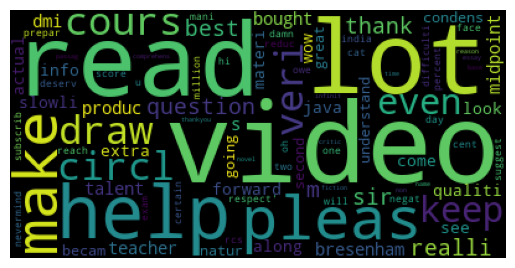

In [ ]:
from wordcloud import WordCloud
text = df[0].values

wordcloud = WordCloud(background_color='black',collocations=False).generate(str(text))

plt.imshow(wordcloud)
plt.axis("off")
plt.show()

## Feature Extaction

In [ ]:
df.shape

(9787, 8)

In [ ]:
#4.5m
import math

N_occurance = 5

words = [df[0][i].split() for i in range(len(df))]
bag_of_words = sorted(list({word for list_ in words for word in list_}))
word_count = {word:0 for word in bag_of_words}
for word in bag_of_words:
    for list_ in words:
        if word in list_:
            word_count[word]+=1
filtered_words = [k for k,v in word_count.items() if v>N_occurance]
evaluation = np.zeros((len(df),len(filtered_words)))
for i in range(len(words)):
    counter = Counter(words[i])
    for k, v in counter.items():
        if k not in filtered_words:
            continue
        count = [1 for list_ in words if k in list_]
        evaluation[i][filtered_words.index(k)] = sum(count)/len(words)

print(filtered_words)
evaluation.shape

['!', '#', '$', '%', '&', "'", "'d", "'m", "'s", '(', ')', '*', '+', ',', '-', '--', '.', '..', '...', '....', '.....', '......', '.......', '........', '.and', '.i', '.x', '/', '//', '//www.youtube.com/watch', ':', ';', '<', '=', '==', '>', '?', '@', '[', ']', '^', '^^', '`', '``', 'a', 'aaa', 'abdul', 'abil', 'abl', 'about', 'abov', 'abroad', 'absolut', 'abstract', 'academ', 'academi', 'accent', 'accept', 'access', 'accord', 'account', 'accuraci', 'ace', 'achiev', 'across', 'act', 'activ', 'actual', 'ad', 'add', 'addit', 'address', 'administr', 'admiss', 'admit', 'advanc', 'advantag', 'advic', 'advis', 'affect', 'afford', 'after', 'again', 'age', 'ago', 'agre', 'agricultur', 'ai', 'aim', 'algorithm', 'alic', 'all', 'alla', 'allow', 'almost', 'along', 'alot', 'alreadi', 'also', 'altern', 'although', 'alway', 'am', 'amaz', 'american', 'among', 'amount', 'an', 'analysi', 'analyst', 'analyt', 'and', 'android', 'angular', 'ani', 'anim', 'annoy', 'anoth', 'answer', 'anybodi', 'anymor', 'an

(9787, 1797)

In [ ]:
features = evaluation
features

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.12465515, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.12465515, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

In [ ]:
from sklearn import preprocessing
features = preprocessing.normalize(evaluation, norm='l2')
features

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
features = scaler.fit_transform(evaluation)

min_max_scaler = preprocessing.MinMaxScaler()
features = min_max_scaler.fit_transform(evaluation)

scaler = preprocessing.RobustScaler()
features = scaler.fit_transform(evaluation)


In [ ]:
type(evaluation)

numpy.ndarray

## Applying models and calculating the scores

c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
c:\Users\Abdul\anaconda3

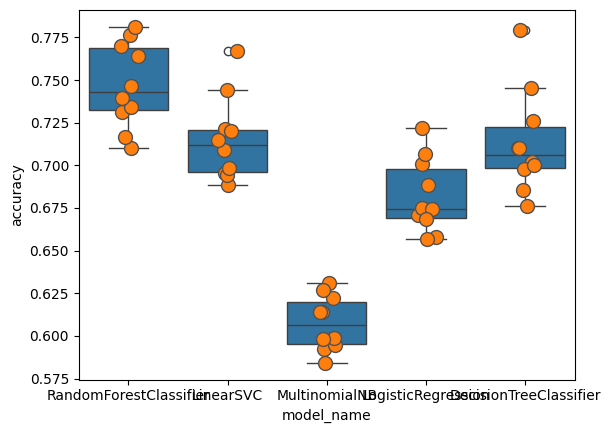

In [ ]:
# Applying models 19 min running time-29 min

labels = df[1]
models = [
    RandomForestClassifier(max_features='log2', n_estimators=1000, criterion = 'entropy',
                           random_state = 0),
    LinearSVC(C=1.0, random_state=0),
    MultinomialNB(alpha=1, fit_prior=True),
    LogisticRegression(C=1.0, penalty='l2', solver='newton-cg', random_state = 0),
    DecisionTreeClassifier(criterion='gini',
                           max_features=None,min_samples_leaf=1,
                           min_samples_split=2, random_state=0),
]

cv_df = pd.DataFrame()
entries = []

for model in models:
  model_name = model.__class__.__name__
  accuracies = cross_val_score(model, features, labels, scoring='accuracy', cv=10)
  for fold_idx, accuracy in enumerate(accuracies):
    entries.append((model_name, fold_idx, accuracy))

cv_df = pd.DataFrame(entries, columns=['model_name', 'fold_idx', 'accuracy'])

import seaborn as sns
sns.boxplot(x='model_name', y='accuracy', data=cv_df)
sns.stripplot(x='model_name', y='accuracy', data=cv_df, size=10, jitter=True, linewidth=1)
plt.show()

In [ ]:
# Printing the accuracies
cv_df.groupby('model_name').accuracy.mean()

model_name
DecisionTreeClassifier    0.713200
LinearSVC                 0.715343
LogisticRegression        0.682135
MultinomialNB             0.607544
RandomForestClassifier    0.747014
Name: accuracy, dtype: float64

In [ ]:
features.shape

(9787, 1797)

## Appyling other models

In [ ]:
X = features
y = df.iloc[:, 1].values
indices = range(len(X))

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, indices_train, indices_test = train_test_split(X, y, indices,
                                                                                 test_size=0.2, random_state=42)

In [ ]:
# for scatter plot -> at the bottom

# Function to show the accuracy of each class
def acc_each_class(cf_matrix):
     total_comments = cf_matrix.sum(axis=1)
     correctly_classified = np.diagonal(cf_matrix)
     incorrectly_classified = total_comments-correctly_classified

     accuracy_each_class = correctly_classified/total_comments
     return accuracy_each_class
     return total_comments, correctly_classified, incorrectly_classified

In [ ]:
# Function to show original category vs predicted category

def show_prediction(y_pred, y_test):

    indices_match = y_pred == y_test


    df = pd.read_csv( path+'final_data.csv', header=None)
    get_comments = []

    for i in range(len(indices_test)):
        get_comments.append(df[0][indices_test[i]])


    data = list(zip(get_comments, y_test, y_pred))
    df_result = pd.DataFrame(data, columns=["comment", "original class", "predicted class"])
    return df_result


In [ ]:
# Multinomial NB
from sklearn.naive_bayes import MultinomialNB

classifier = MultinomialNB(alpha=0.1, fit_prior=True)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_mnb = confusion_matrix(y_test, y_pred)


print("accuracy score: " + str(classifier.score(X_test, y_test)))

accuracy score: 0.6537282941777324


In [ ]:
# define initials
acc_corrective = [];
acc_imperative = [];
acc_interrogative = [];
acc_miscellaneous = [];
acc_negative = [];
acc_positive = [];

In [ ]:
accuracies = acc_each_class(cm_mnb)

acc_corrective.append(accuracies[0])
acc_imperative.append(accuracies[1])
acc_interrogative.append(accuracies[2])
acc_miscellaneous.append(accuracies[3])
acc_negative.append(accuracies[4])
acc_positive.append(accuracies[5])

In [ ]:
# ### Hyperparameter Tuning ###

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV


model = MultinomialNB()
fit_prior=[True]
alpha=[0,0.1,1]


grid = dict(fit_prior=fit_prior,alpha=alpha)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1,
                            cv=cv, scoring='accuracy',error_score=0)
grid_result = grid_search.fit(X_train, y_train)

print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
  print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.706603 using {'alpha': 0, 'fit_prior': True}
0.706603 (0.009847) with: {'alpha': 0, 'fit_prior': True}
0.642908 (0.009521) with: {'alpha': 0.1, 'fit_prior': True}
0.603823 (0.007472) with: {'alpha': 1, 'fit_prior': True}


c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:624: FutureWarning: The default value for `force_alpha` will change to `True` in 1.4. To suppress this warning, manually set the value of `force_alpha`.
  warnings.warn(
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:633: UserWarning: alpha too small will result in numeric errors, setting alpha = 1.0e-10. Use `force_alpha=True` to keep alpha unchanged.
  warnings.warn(


In [ ]:
show_prediction(y_pred, y_test)

,comment,original class,predicted class
0,"Hello sir, i want to do my masters in aerospac...",interrogative,interrogative
1,Really helpful video..... if you guys can make...,positive,positive
2,sounds much better..thanks,interrogative,interrogative
3,Thank you 🌷,interrogative,interrogative
4,I am here for Kylie Ying🤩,positive,positive
...,...,...,...
1953,The very first,positive,positive
1954,Please make a backend video,positive,positive
1955,Great video!,imperative,positive
1956,There must be a comma after the first element ...,positive,positive


In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(C=1.0, penalty='l1', solver='liblinear', random_state = 0)
classifier.fit(X_train, y_train)

# Predicting the Test set results
y_pred = classifier.predict(X_test)

# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test, y_pred)

print("accuracy score: " + str(classifier.score(X_test, y_test)))

accuracy score: 0.7124616956077631


In [ ]:
cm_lr

array([[  0,   0,   6,  16,   2,   3],
       [  0,  58,  21,   1,   0, 109],
       [  0,  16, 507,   1,   0, 111],
       [  0,   0,  29, 134,   1, 147],
       [  0,   0,   4,   1,  10,  79],
       [  0,   4,  12,   0,   0, 686]], dtype=int64)

In [ ]:
 accuracies = acc_each_class(cm_lr)

acc_corrective.append(accuracies[0])
acc_imperative.append(accuracies[1])
acc_interrogative.append(accuracies[2])
acc_miscellaneous.append(accuracies[3])
acc_negative.append(accuracies[4])
acc_positive.append(accuracies[5])

In [ ]:
# ### Hyperparameter Tuning ###

#from sklearn.model_selection import RepeatedStratifiedKFold
#from sklearn.model_selection import GridSearchCV
#from sklearn.linear_model import LogisticRegression

# # define models and parameters
#model = LogisticRegression()
#solvers = ['newton-cg', 'lbfgs', 'liblinear']
#penalty = ['l1', 'l2', 'elasticnet', 'none']
#c_values = [100, 10, 1.0, 0.1, 0.01]
# # define grid search
#grid = dict(solver=solvers,penalty=penalty,C=c_values)
#cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
#grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, cv=cv, scoring='accuracy',error_score=0)
#grid_result = grid_search.fit(X_train, y_train)
# # summarize results
#print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
#means = grid_result.cv_results_['mean_test_score']
#stds = grid_result.cv_results_['std_test_score']
#params = grid_result.cv_results_['params']
#for mean, stdev, param in zip(means, stds, params):
#  print("%f (%f) with: %r" % (mean, stdev, param))

In [ ]:
show_prediction(y_pred, y_test)

,comment,original class,predicted class
0,"Hello sir, i want to do my masters in aerospac...",interrogative,interrogative
1,Really helpful video..... if you guys can make...,positive,positive
2,sounds much better..thanks,interrogative,interrogative
3,Thank you 🌷,interrogative,interrogative
4,I am here for Kylie Ying🤩,positive,positive
...,...,...,...
1953,The very first,positive,positive
1954,Please make a backend video,positive,positive
1955,Great video!,imperative,positive
1956,There must be a comma after the first element ...,positive,positive


In [ ]:
# # Naive Bayes
from sklearn.naive_bayes import GaussianNB

classifier = GaussianNB()
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

print("accuracy score: " + str(classifier.score(X_test, y_test)))

accuracy score: 0.42083758937691523


In [ ]:
 accuracies = acc_each_class(cm)

 acc_corrective.append(accuracies[0])
 acc_imperative.append(accuracies[1])
 acc_interrogative.append(accuracies[2])
 acc_miscellaneous.append(accuracies[3])
 acc_negative.append(accuracies[4])
 acc_positive.append(accuracies[5])

In [ ]:
#hyperparameter tuning (1m) orignal
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix


classifier = GaussianNB()
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

var_smoothing_values = [1e-9, 1e-8, 1e-5, 1e-3, 1e-2, 0]
param_grid = {'var_smoothing': var_smoothing_values}

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=classifier, param_grid=param_grid, cv=cv, scoring='accuracy', error_score=0)

grid_result = grid_search.fit(X_train, y_train)


print("Best GNB Hyperparameters:", grid_result.best_params_)
print("Best GNB " + grid_search.scoring + " Score:", grid_result.best_score_)


best_var_smoothing = grid_result.best_params_['var_smoothing']
best_classifier = GaussianNB(var_smoothing=best_var_smoothing)
best_classifier.fit(X_train, y_train)

y_pred_best = best_classifier.predict(X_test)
best_accuracy = best_classifier.score(X_test, y_test)
print("Best GNB Accuracy Score on Test Set:", best_accuracy)


cm = confusion_matrix(y_test, y_pred_best)
print("Confusion Matrix:")
print(cm)


precision = cm[1, 1] / (cm[1, 1] + cm[0, 1])
recall = cm[1, 1] / (cm[1, 1] + cm[1, 0])
f1_score = 2 * (precision * recall) / (precision + recall)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1_score)


accuracy = classifier.score(X_test, y_test)
print("Initial Accuracy Score:", accuracy)


c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:510: RuntimeWarning: divide by zero encountered in log
  n_ij = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[i, :]))
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:511: RuntimeWarning: divide by zero encountered in divide
  n_ij -= 0.5 * np.sum(((X - self.theta_[i, :]) ** 2) / (self.var_[i, :]), 1)
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:511: RuntimeWarning: invalid value encountered in divide
  n_ij -= 0.5 * np.sum(((X - self.theta_[i, :]) ** 2) / (self.var_[i, :]), 1)
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:510: RuntimeWarning: divide by zero encountered in log
  n_ij = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[i, :]))
c:\Users\Abdul\anaconda3\envs\env\Lib\site-packages\sklearn\naive_bayes.py:511: RuntimeWarning: divide by zero encountered in divide
  n_ij -= 0.5 * np.sum(((X - self.theta_[i, :]) ** 2) / (self.

Best GNB Hyperparameters: {'var_smoothing': 1e-05}
Best GNB accuracy Score: 0.7010267197555905
Best GNB Accuracy Score on Test Set: 0.7032686414708886
Confusion Matrix:
[[ 16   0   0   8   0   3]
 [  0  96   3   0  11  79]
 [  3  71 447   2  20  92]
 [ 29   2   0 149   7 124]
 [  0   8   0   0  34  52]
 [  1  29   3   0  34 635]]
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Initial Accuracy Score: 0.42083758937691523


In [ ]:
# # Kernal SVC RBF
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
classifier = SVC(kernel = 'rbf', random_state = 0)
classifier.fit(X_train, y_train)


y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_k_svc = confusion_matrix(y_test, y_pred)

print("accuracy score: " + str(classifier.score(X_test, y_test)))

accuracy score: 0.6869254341164454


In [ ]:
 accuracies = acc_each_class(cm_k_svc)

 acc_corrective.append(accuracies[0])
 acc_imperative.append(accuracies[1])
 acc_interrogative.append(accuracies[2])
 acc_miscellaneous.append(accuracies[3])
 acc_negative.append(accuracies[4])
 acc_positive.append(accuracies[5])

In [ ]:
#Hyperpar# Kernel SVC RBF
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


classifier = SVC(kernel='rbf', random_state=0)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)


cm_k_svc = confusion_matrix(y_test, y_pred)
print("Accuracy score:", round(classifier.score(X_test, y_test), 4))


from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # Use a new scaler for the test set

#tuning
param_grid = {'C': [0.01], 'gamma': [0.001, 0.01], 'kernel': ['rbf']}
grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=3)
grid.fit(X_train_scaled, y_train)
print("Best parameters:", grid.best_params_)
classifier = grid.best_estimator_


accuracies = cross_val_score(estimator=classifier, X=X_train_scaled, y=y_train, cv=10)
print("Cross-validated accuracy:", round(accuracies.mean(), 4))


y_pred = classifier.predict(X_test_scaled)
cm_k_svc = confusion_matrix(y_test, y_pred)
print("Accuracy score:", round(classifier.score(X_test_scaled, y_test), 4))


Accuracy score: 0.6869
Fitting 5 folds for each of 2 candidates, totalling 10 fits
[CV 1/5] END ...C=0.01, gamma=0.001, kernel=rbf;, score=0.422 total time= 1.1min
[CV 2/5] END ...C=0.01, gamma=0.001, kernel=rbf;, score=0.434 total time= 1.1min
[CV 3/5] END ...C=0.01, gamma=0.001, kernel=rbf;, score=0.411 total time= 1.1min
[CV 4/5] END ...C=0.01, gamma=0.001, kernel=rbf;, score=0.411 total time= 1.1min
[CV 5/5] END ...C=0.01, gamma=0.001, kernel=rbf;, score=0.427 total time= 1.1min
[CV 1/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.402 total time= 1.2min
[CV 2/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.418 total time= 1.2min
[CV 3/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.382 total time= 1.2min
[CV 4/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.395 total time= 1.2min
[CV 5/5] END ....C=0.01, gamma=0.01, kernel=rbf;, score=0.401 total time= 1.2min
Best parameters: {'C': 0.01, 'gamma': 0.001, 'kernel': 'rbf'}
Cross-validated accuracy: 0.422
Accuracy scor

In [ ]:
# Random Forest  2min
from sklearn.ensemble import RandomForestClassifier


classifier = RandomForestClassifier(max_features='log2', n_estimators=1000, criterion = 'entropy', random_state = 0)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_rf = confusion_matrix(y_test, y_pred)

print("accuracy score: " + str(classifier.score(X_test, y_test)))

accuracy score: 0.7599591419816139


In [ ]:
# accuracies = acc_each_class(cm_rf)

## acc_corrective.append(accuracies[0])
# acc_imperative.append(accuracies[1])
# acc_interrogative.append(accuracies[2])
# acc_miscellaneous.append(accuracies[3])
# acc_negative.append(accuracies[4])
# acc_positive.append(accuracies[5])

In [ ]:
# ### Hyperparameter Tuning  142 min

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier


model = RandomForestClassifier()
n_estimators = [10, 50]
max_features = [None, 'sqrt', 'log2']
criterion = ['gini', 'entropy']

grid = dict(n_estimators=n_estimators,max_features=max_features,criterion=criterion)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, cv=cv, scoring='accuracy',error_score=0)
grid_result = grid_search.fit(X_train, y_train)

print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

Best: 0.766339 using {'criterion': 'gini', 'max_features': 'sqrt', 'n_estimators': 50}
0.740367 (0.012088) with: {'criterion': 'gini', 'max_features': None, 'n_estimators': 10}
0.745603 (0.011490) with: {'criterion': 'gini', 'max_features': None, 'n_estimators': 50}
0.752459 (0.012786) with: {'criterion': 'gini', 'max_features': 'sqrt', 'n_estimators': 10}
0.766339 (0.012620) with: {'criterion': 'gini', 'max_features': 'sqrt', 'n_estimators': 50}
0.731342 (0.013961) with: {'criterion': 'gini', 'max_features': 'log2', 'n_estimators': 10}
0.754162 (0.012993) with: {'criterion': 'gini', 'max_features': 'log2', 'n_estimators': 50}
0.740111 (0.012572) with: {'criterion': 'entropy', 'max_features': None, 'n_estimators': 10}
0.745263 (0.012654) with: {'criterion': 'entropy', 'max_features': None, 'n_estimators': 50}
0.751947 (0.012015) with: {'criterion': 'entropy', 'max_features': 'sqrt', 'n_estimators': 10}
0.763230 (0.012975) with: {'criterion': 'entropy', 'max_features': 'sqrt', 'n_estima

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

best_params = grid_result.best_params_
final_model = RandomForestClassifier(**best_params)
final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)
accuracy_final = accuracy_score(y_test, y_pred_final)
cm_final = confusion_matrix(y_test, y_pred_final)


print("Best hyperparameters:", best_params)
print("Accuracy (final model):", accuracy_final)
print("Confusion Matrix (final model):\n", cm_final)

Best hyperparameters: {'criterion': 'gini', 'max_features': 'sqrt', 'n_estimators': 50}
Accuracy (final model): 0.7732379979570991
Confusion Matrix (final model):
 [[  1   0   1  21   1   3]
 [  0  90  25   3   1  70]
 [  0   6 534   3   0  92]
 [  0   1   6 187   1 116]
 [  0   0   6   1  22  65]
 [  0   6  10   4   2 680]]


In [ ]:
accuracies = acc_each_class(cm_final)

acc_corrective.append(accuracies[0])
acc_imperative.append(accuracies[1])
acc_interrogative.append(accuracies[2])
acc_miscellaneous.append(accuracies[3])
acc_negative.append(accuracies[4])
acc_positive.append(accuracies[5])


In [ ]:
 # Show falsely predicted comments

def show_neg_prediction(y_pred, y_test):

    indices_match = y_pred == y_test

    df = pd.read_csv('Scrapper/final.csv', header=None)

    get_comments = []

    for i in range(len(indices_test)):
        if indices_match[i] == False:
            get_comments.append(df[0][indices_test[i]])


    data = list(zip(get_comments, y_test, y_pred))
    df_result = pd.DataFrame(data, columns = ["comment", "original class", "predicted class"])
    return df_result

In [ ]:
df_ = show_prediction(y_pred, y_test)
pd.options.display.max_colwidth = 150
df_.iloc[200:250]


,comment,original class,predicted class
200,"U r great sir, yrr method of teaching this sub is too excellent.you make this sub easier.",miscellaneous,miscellaneous
201,How many of you here cracked the FANG after going through this course directly and no other material . How many of you are able to solve the mediu...,negative,positive
202,Plz! Make A Blender Tutorial Too,miscellaneous,miscellaneous
203,I am a beginner and was wondering what IDE is she using.,positive,positive
204,Thanks bruhh!! It helped me a lot😎,imperative,interrogative
205,A very informative video! thank you. I'm graduating BSc I.T. 2020 from India and am working as an HR Intern. I want to pursue MBA (Human Resource...,interrogative,interrogative
206,English is my 3rd language and I am struggling with GRE Verbal section a lot. I am practicing 20 GRE words every day but sometimes I can not under...,negative,interrogative
207,Who else just randomly found his channel and now watching his videos are a daily thing 😂,positive,positive
208,"“Don’t compare yourself to me” - I kind of liked it, superb.",imperative,imperative
209,Abdul Sir aap na hote toh yahan back pe back lag rhi hoti algo ds mein. Thanks,positive,positive


In [ ]:
# Decision Tree
# from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier(criterion='gini',
                                    max_features=None,min_samples_leaf=1, max_depth = 16,
                                    min_samples_split=2, random_state=0)

classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_dt = confusion_matrix(y_test, y_pred)

print("accuracy score: " + str(classifier.score(X_test, y_test)))

accuracy score: 0.719611848825332


Best: 0.728360 using {'criterion': 'gini', 'max_depth': 26, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 10}
0.616804 (0.040552) with: {'criterion': 'gini', 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
0.614857 (0.046961) with: {'criterion': 'gini', 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 3}
0.617403 (0.036710) with: {'criterion': 'gini', 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 4}
0.621618 (0.042689) with: {'criterion': 'gini', 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5}
0.597482 (0.036241) with: {'criterion': 'gini', 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 6}
0.613702 (0.037647) with: {'criterion': 'gini', 'max_depth': 22, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 7}
0.615317 (0.037043) with: {'criterion': 'gini', 'max_d

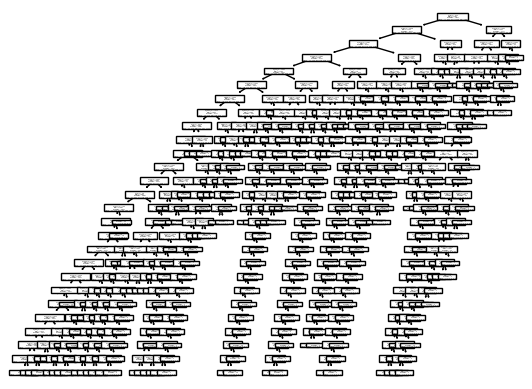

In [ ]:
# Decision Tree Tuning 42 min
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import tree
# ### Hyperparameter Tuning ###

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV


model = DecisionTreeClassifier()
max_features = ['sqrt', 'log2', None]
criterion = ['gini', 'entropy']
max_depth = [22, 24, 26]
min_samples_split = range(2, 15)
min_samples_leaf = range(1, 5)

#  grid search
grid = dict(max_depth=max_depth, max_features=max_features, criterion=criterion, min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, cv=cv, scoring='accuracy', error_score=0)
grid_result = grid_search.fit(X_train, y_train)


print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print("%f (%f) with: %r" % (mean, stdev, param))

classifier = DecisionTreeClassifier(**grid_result.best_params_, random_state=0)
classifier.fit(X_train, y_train)


y_pred = classifier.predict(X_test)

from sklearn.metrics import confusion_matrix
cm_dt = confusion_matrix(y_test, y_pred)


accuracy_test = accuracy_score(y_test, y_pred)
print("Accuracy score on the test set: " + str(accuracy_test))


tree.export_graphviz(classifier, out_file='tree.dot')
tree.plot_tree(classifier)


print("Confusion Matrix:", cm_dt)
print("accuracy score: " + str(classifier.score(X_test, y_test)))

In [ ]:
 accuracies = acc_each_class(cm_dt)

 acc_corrective.append(accuracies[0])
 acc_imperative.append(accuracies[1])
 acc_interrogative.append(accuracies[2])
 acc_miscellaneous.append(accuracies[3])
 acc_negative.append(accuracies[4])
 acc_positive.append(accuracies[5])

In [ ]:
#from sklearn import tree
# tree.export_graphviz(classifier, out_file='tree.dot')
# tree.plot_tree(classifier)

In [ ]:
show_prediction(y_pred, y_test)

,comment,original class,predicted class
0,"Hello sir, i want to do my masters in aerospace engineering with non-thesis program!",interrogative,interrogative
1,Really helpful video..... if you guys can make a video on MS Project and its functioning in different scenarios...,positive,positive
2,sounds much better..thanks,interrogative,interrogative
3,Thank you 🌷,interrogative,imperative
4,I am here for Kylie Ying🤩,positive,positive
...,...,...,...
1953,The very first,positive,imperative
1954,Please make a backend video,positive,positive
1955,Great video!,imperative,positive
1956,"There must be a comma after the first element to make a tuple (""age"",).",positive,positive


## Histogram

In [ ]:
def acc_each_category(cf_matrix):
#     total_comments = cf_matrix.sum(axis=1)
    correctly_classified = np.diagonal(cf_matrix)
    return correctly_classified

y = cm_dt.sum(axis=1)

In [ ]:
z1 = acc_each_category(cm_mnb)
z2 = acc_each_category(cm_lr)
z3 = acc_each_category(cm) #gnb
z4 = acc_each_category(cm_k_svc)
z5 = acc_each_category(cm_final) #cm_rt
z6 = acc_each_category(cm_dt)

#z1 = acc_each_category(cm_k_svc)
#z2 = acc_each_category(cm)
#z3 = acc_each_category(cm_mnb)
#z4 = acc_each_category(cm_rf)
#z5 = acc_each_category(cm_dt)
#z6 = acc_each_category(cm_lr)

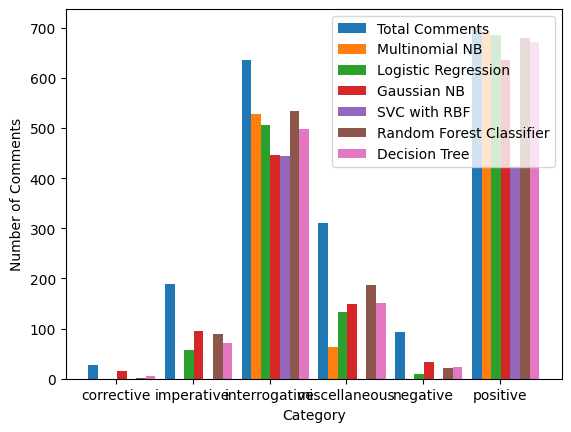

In [ ]:
import matplotlib.pyplot as plt

x_tick = np.unique(y_test)
w = 0.125
x1 = np.array([1,2,3,4,5,6])
x2 = x1+w
x3 = x2+w
x4 = x3+w
x5 = x4+w
x6 = x5+w
x7 = x6+w
x8 = x7+w

plt.xticks(ticks=x1+0.3, labels=x_tick)
plt.bar(x1, y, w, label = "Total Comments")
plt.bar(x2, z1, w, label = "Multinomial NB")
plt.bar(x3, z2, w, label = "Logistic Regression",)
plt.bar(x4, z3, w, label = "Gaussian NB",)
plt.bar(x5, z4, w, label = "SVC with RBF")
plt.bar(x6, z5, w, label = "Random Forest Classifier")
plt.bar(x7, z6, w, label = "Decision Tree",)


plt.rcParams["figure.figsize"] = (15,5)
plt.xlabel("Category")
plt.ylabel("Number of Comments")
plt.legend()
plt.show()

## Percentage of accuracy in each class

In [ ]:
corr = [i * 100 for i in acc_corrective]
imp = [i * 100 for i in acc_imperative]
inte = [i * 100 for i in acc_interrogative]
mis = [i * 100 for i in acc_miscellaneous]
neg = [i * 100 for i in acc_negative]
pos = [i * 100 for i in acc_positive]

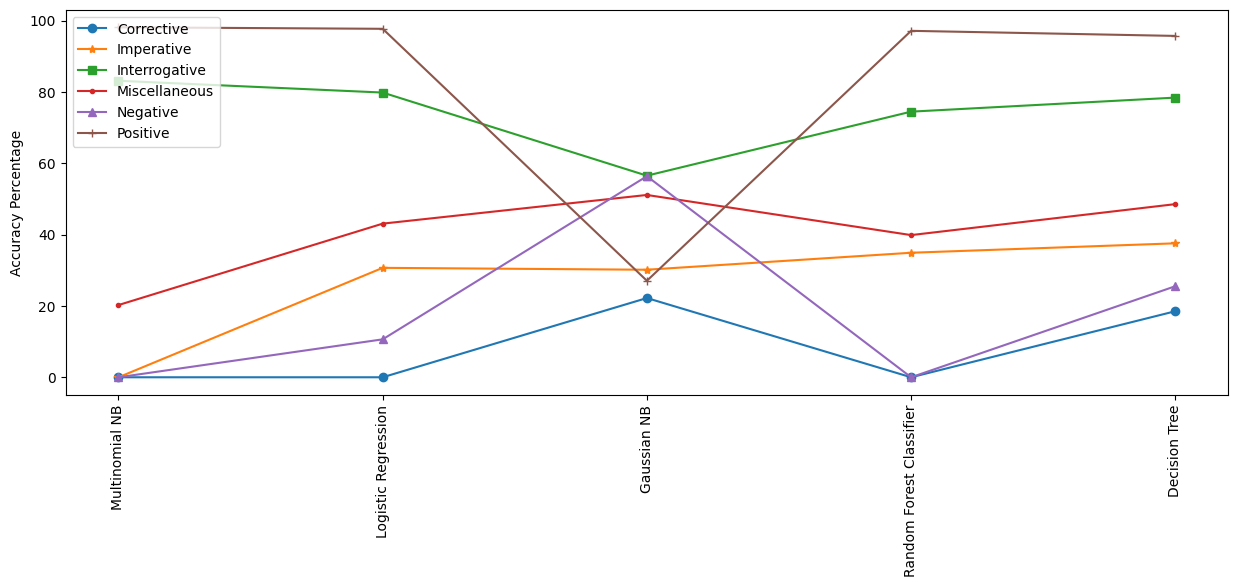

In [ ]:
import matplotlib.pyplot as plt


x1 = ["Multinomial NB","Logistic Regression","Gaussian NB","Random Forest Classifier","Decision Tree"]
# corrective
y1 = corr
# plotting the line 1 points
plt.plot(x1, y1, label = "Corrective", marker='o')

# imperative
y2 = imp
# plotting the line 2 points
plt.plot(x1, y2, label = "Imperative", marker='*')

# interrogative
y3 = inte
# plotting the line 2 points
plt.plot(x1, y3, label = "Interrogative", marker='s')

# Miscellaneous
y4 = mis
# plotting the line 2 points
plt.plot(x1, y4, label = "Miscellaneous", marker='.')

# Negative
y5 = neg
# plotting the line 2 points
plt.plot(x1, y5, label = "Negative", marker='^')

# Positive
y6 = pos
# plotting the line 2 points
plt.plot(x1, y6, label = "Positive", marker='+')


plt.xlabel('')
# Set the y axis label of the current axis.
plt.ylabel('Accuracy Percentage')
# Set a title of the current axes.
plt.title('')
# show a legend on the plot
plt.legend(loc='upper left')

plt.xticks(rotation=90)
# Display a figure.
plt.show()

## Plotting accuracy vs data size

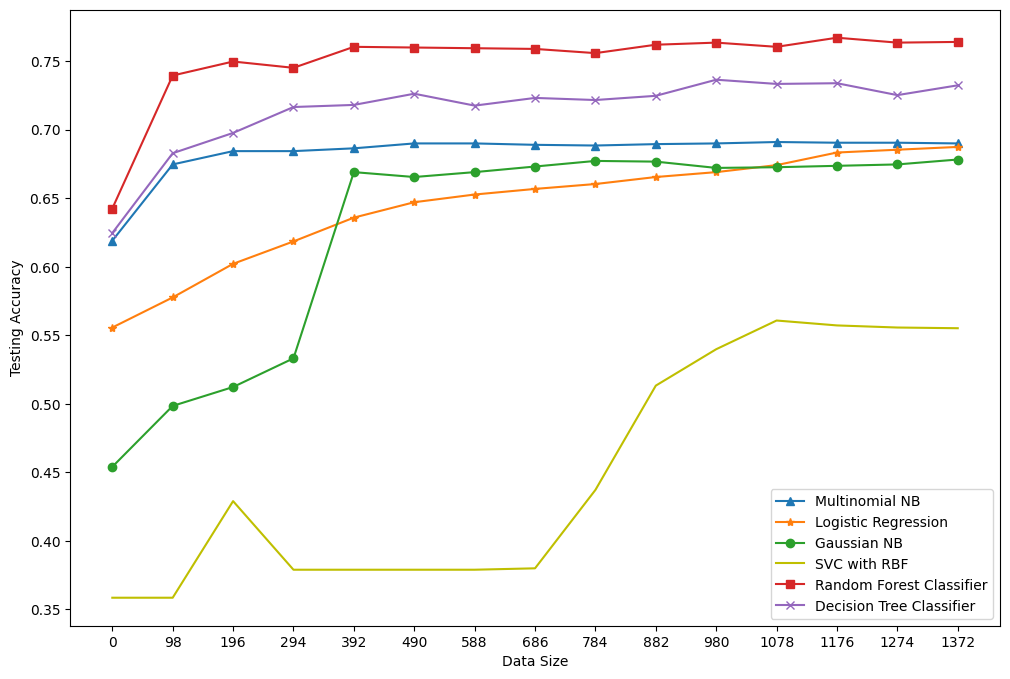

In [ ]:
def plot_acc_curve(classifier, linestyle, label): #10min

    num_of_splits = 14
    each_split_size = len(X_train)//num_of_splits

    each_split = 98
    scores = []

    for i in range(num_of_splits+1):
        split_X_train = X_train[0:each_split]
        split_y_train = y_train[0:each_split]

        each_split += each_split_size

        classifier.fit(split_X_train, split_y_train)
        scores.append(classifier.score(X_test, y_test))

    m = 14
    n = 98
    x_splits = list(range(0, (m+1)*n, n))

    plt.xlabel('Data Size')
    plt.ylabel('Testing Accuracy')
    plt.plot(x_splits, scores, linestyle, label = label)
    plt.xticks(x_splits)
    plt.legend(loc="best")

    return plt


plt.figure(figsize=(12,8))


# Multinomial NB
classifier = MultinomialNB(alpha=0.001, fit_prior=True)
plot_acc_curve(classifier, linestyle = '^-', label="Multinomial NB")
# Logistic Regression
classifier = LogisticRegression(C=1.0, penalty='l2', solver='newton-cg', random_state = 0)
plot_acc_curve(classifier, linestyle = '*-', label="Logistic Regression")
# Gaussian NB
classifier = GaussianNB(var_smoothing=1e-3)
plot_acc_curve(classifier, linestyle = 'o-', label="Gaussian NB")
# SVC with RBF
classifier = SVC(C= 10, gamma= 0.001, kernel = 'rbf', random_state = 0)
plot_acc_curve(classifier, linestyle = 'y-', label="SVC with RBF")
# Random Forest Classifier
classifier = RandomForestClassifier(max_features='sqrt', n_estimators=50, criterion = 'gini', random_state = 0)
plot_acc_curve(classifier, linestyle = 's-', label="Random Forest Classifier")
# Decision Tree Classifier
classifier = DecisionTreeClassifier(criterion='gini',
                                    max_features=None, min_samples_leaf=1, max_depth =26,
                                    min_samples_split=12, random_state=0)
plot_acc_curve(classifier, linestyle = 'x-', label="Decision Tree Classifier")

plt.show()

## PLotting the learning curves

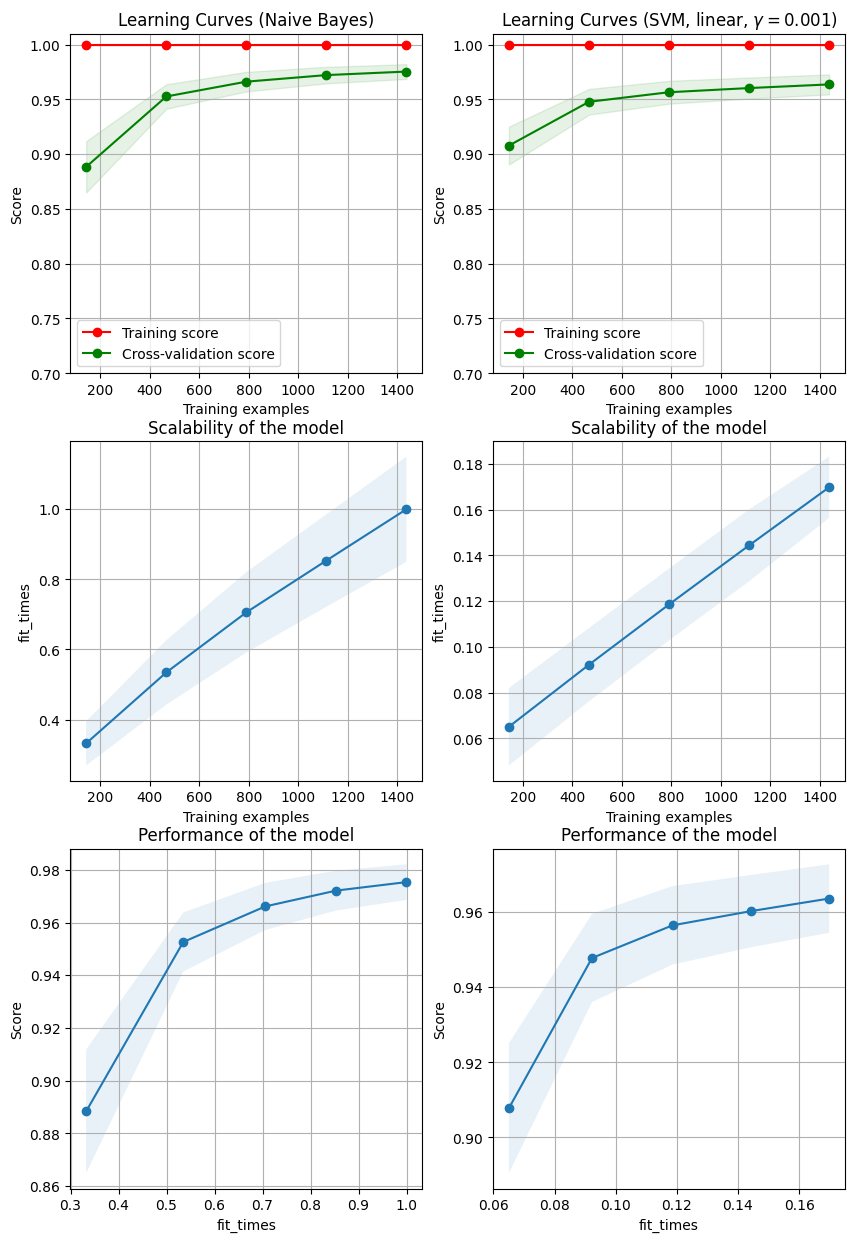

In [ ]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.datasets import load_digits
from sklearn.model_selection import learning_curve
from sklearn.model_selection import ShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def plot_learning_curve(estimator, title, X, y, axes=None, ylim=None, cv=None,
                         n_jobs=None, train_sizes=np.linspace(.1, 1.0, 5)):

     if axes is None:
         _, axes = plt.subplots(1, 3, figsize=(20, 5))

     axes[0].set_title(title)
     if ylim is not None:
         axes[0].set_ylim(*ylim)
     axes[0].set_xlabel("Training examples")
     axes[0].set_ylabel("Score")

     train_sizes, train_scores, test_scores, fit_times, _ = \
         learning_curve(estimator, X, y, cv=cv, n_jobs=n_jobs,
                        train_sizes=train_sizes,
                        return_times=True)
     train_scores_mean = np.mean(train_scores, axis=1)
     train_scores_std = np.std(train_scores, axis=1)
     test_scores_mean = np.mean(test_scores, axis=1)
     test_scores_std = np.std(test_scores, axis=1)
     fit_times_mean = np.mean(fit_times, axis=1)
     fit_times_std = np.std(fit_times, axis=1)

     # Plot learning curve
     axes[0].grid()
     axes[0].fill_between(train_sizes, train_scores_mean - train_scores_std,
                          train_scores_mean + train_scores_std, alpha=0.1,
                          color="r")
     axes[0].fill_between(train_sizes, test_scores_mean - test_scores_std,
                          test_scores_mean + test_scores_std, alpha=0.1,
                          color="g")
     axes[0].plot(train_sizes, train_scores_mean, 'o-', color="r",
                  label="Training score")
     axes[0].plot(train_sizes, test_scores_mean, 'o-', color="g",
                  label="Cross-validation score")
     axes[0].legend(loc="best")
     # Plot n_samples vs fit_times
     axes[1].grid()
     axes[1].plot(train_sizes, fit_times_mean, 'o-')
     axes[1].fill_between(train_sizes, fit_times_mean - fit_times_std,
                          fit_times_mean + fit_times_std, alpha=0.1)
     axes[1].set_xlabel("Training examples")
     axes[1].set_ylabel("fit_times")
     axes[1].set_title("Scalability of the model")

     # Plot fit_time vs score
     axes[2].grid()
     axes[2].plot(fit_times_mean, test_scores_mean, 'o-')
     axes[2].fill_between(fit_times_mean, test_scores_mean - test_scores_std,
                          test_scores_mean + test_scores_std, alpha=0.1)
     axes[2].set_xlabel("fit_times")
     axes[2].set_ylabel("Score")
     axes[2].set_title("Performance of the model")

     return plt


fig, axes = plt.subplots(3, 2, figsize=(10, 15))

X, y = load_digits(return_X_y=True)

title = "Learning Curves (Naive Bayes)"
# # Cross validation with 100 iterations to get smoother mean test and train
# # score curves, each time with 20% data randomly selected as a validation set.
cv = ShuffleSplit(n_splits=100, test_size=0.2, random_state=0)

estimator = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 0)
plot_learning_curve(estimator, title, X, y, axes=axes[:, 0], ylim=(0.7, 1.01),
                     cv=cv, n_jobs=4)

title = r"Learning Curves (SVM, linear, $\gamma=0.001$)"
# # SVC is more expensive so we do a lower number of CV iterations:
# cv = ShuffleSplit(n_splits=10, test_size=0.2, random_state=0)
estimator = LogisticRegression(random_state = 0)
plot_learning_curve(estimator, title, X, y, axes=axes[:, 1], ylim=(0.7, 1.01),
                     cv=cv, n_jobs=4)

plt.show()

## Creating a json file and sending to the server

In [ ]:
# cm_rf_p = cm_rf.astype('float') / cm_rf.sum(axis=1)[:, np.newaxis]
# cm_lr_p = cm_lr.astype('float') / cm_lr.sum(axis=1)[:, np.newaxis]
# cm_knn_p = cm_knn.astype('float') / cm_knn.sum(axis=1)[:, np.newaxis]
# cm_k_svc_p = cm_k_svc.astype('float') / cm_k_svc.sum(axis=1)[:, np.newaxis]
# cm_dt_p = cm_dt.astype('float') / cm_dt.sum(axis=1)[:, np.newaxis]

In [ ]:
# unique, counts = np.unique(y_pred, return_counts=True)

In [ ]:
# dict_pred_rf = dict(zip(unique, cm_rf_p.diagonal()))
# dict_pred_lr = dict(zip(unique, cm_lr_p.diagonal()))
# dict_pred_knn = dict(zip(unique, cm_knn_p.diagonal()))
# dict_pred_k_svc = dict(zip(unique, cm_k_svc_p.diagonal()))
# dict_pred_dt = dict(zip(unique, cm_dt_p.diagonal()))

In [ ]:
# import json

# models = ['random_forest', 'linear_regression', 'knn', 'kernal_svc', 'decision_tree']
# pred_dict = [dict_pred_rf, dict_pred_lr, dict_pred_knn, dict_pred_k_svc, dict_pred_dt]

# predictions = {}
# for model, pred in zip(models, pred_dict):
#     predictions[model] = pred

# with open('prediction.json', 'w') as json_file:
#     json.dump(predictions, json_file)

In [ ]:
# predictions

In [ ]:
# To DO:
# Send json